# Module Assignment — Exploratory Data Analysis on Hotel Bookings

## Case Study: Hotel Bookings

In this assignment you'll apply everything from this module to a **large, genuinely messy** real-world dataset: **119,390 hotel bookings with 32 columns**.

You will practise the full EDA workflow:

1. **Exploring / diagnosing** the data
2. **Cleaning** — missing values, duplicates, wrong data types, invalid values
3. **Visualizing** with matplotlib
4. **Manipulating** — sorting, filtering, new columns, `groupby`, `pivot_table`, `crosstab`
5. **Drawing conclusions**

**This dataset is deliberately challenging** — it has 4 columns with missing data (one is ~94% empty!), ~32,000 duplicate rows, dates stored as text, and some physically impossible values. Read each prompt carefully and think about *why* a step is needed, not just *how*.

### Instructions

- Write your **full code** in the empty cell below each exercise
- Some exercises ask a question in **markdown** — answer it in a comment or a short written note.
- Work through the notebook **in order**: later sections rely on the cleaned DataFrame from earlier ones.
- Worked answers are in **`Module_Assignment_Hotel_Bookings_Solutions.ipynb`** — try hard before peeking.

### Key columns

| Column | Meaning |
|---|---|
| `hotel` | Resort Hotel or City Hotel |
| `is_canceled` | 1 = booking was cancelled, 0 = not |
| `lead_time` | Days between booking and arrival |
| `arrival_date_month` | Month of arrival (text, e.g. "July") |
| `adults` / `children` / `babies` | Number of guests of each type |
| `meal`, `country`, `market_segment`, `customer_type` | Categorical descriptors |
| `adr` | Average Daily Rate (price per night) |
| `agent` / `company` | IDs of the booking agent / company (lots of missing) |
| `reservation_status_date` | Date of the last status change (text) |

## Import Libraries

**Exercise 0.** Import the required libraries.

In [2]:
# Your code here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("hotel_bookings.csv")
df.head()         

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## Load Dataset

**Exercise 1.** Read `hotel_bookings.csv` into a DataFrame called `df` and display the first 5 rows.

In [5]:
# Your code here
df = pd.read_csv("hotel_bookings.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


# 1. Exploring / Diagnosing the Data

**Exercise 2.** Report the dataset's **shape** (rows, columns). Then  inspect column names, non-null counts, and dtypes.

In [6]:
# Your code here
print(df.shape)
df.info()     

(119390, 32)
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal          

**Exercise 3.** Show the summary statistics for the **numeric** columns `. Look at the `adr` column — what is suspicious about its **minimum** value?

In [7]:
# Your code here
df.describe()     

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


**Exercise 4.** Build a table showing, **for every column**, the number of missing values **and** the percentage missing — sorted from most to least missing. Which columns are the worst?

In [8]:
# Your code here
missing = df.isnull().sum()                       
missing_pct = (missing / len(df)) * 100
missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct.round(2)
}).sort_values("missing_pct", ascending=False)

missing_table

,missing_count,missing_pct
company,112593,94.31
agent,16340,13.69
country,488,0.41
hotel,0,0.00
arrival_date_month,0,0.00
arrival_date_week_number,0,0.00
lead_time,0,0.00
is_canceled,0,0.00
stays_in_weekend_nights,0,0.00
stays_in_week_nights,0,0.00


**Exercise 5.** For the categorical columns `hotel`, `meal`, `customer_type` and `market_segment`, print the **count of each unique value**.

In [9]:
# Your code here
for col in ["hotel", "meal", "customer_type", "market_segment"]:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()

--- hotel ---
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

--- meal ---
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

--- customer_type ---
customer_type
Transient          89613
Transient-Party    25124
Contract            4076
Group                577
Name: count, dtype: int64

--- market_segment ---
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64



# 2. Cleaning the Data

Work on a copy so the raw data stays intact: start this section with `df_clean = df.copy()`.

**Exercise 6.** Make a copy called `df_clean`. Then handle the missing values:

- `children` → fill missing with `0`
- `country` → fill missing with `"Unknown"`
- `company` and `agent` are mostly empty → **drop both columns**

Confirm there are no missing values left.

In [10]:
# Your code here
df_clean = df.copy()

df_clean["children"] = df_clean["children"].fillna(0)
df_clean["country"]  = df_clean["country"].fillna("Unknown")
df_clean = df_clean.drop(columns=["company", "agent"])

df_clean.isnull().sum().sum()   

np.int64(0)

**Exercise 7.** How many **fully duplicated rows** does `df_clean` contain? Remove them, then confirm the count is now 0 and report the new shape.

In [11]:
# Your code here
print("Duplicates before:", df_clean.duplicated().sum()) 

df_clean = df_clean.drop_duplicates()

print("Duplicates after:", df_clean.duplicated().sum())    
print("New shape:", df_clean.shape)                   

Duplicates before: 32020
Duplicates after: 0
New shape: (87370, 30)


**Exercise 8.** Fix the data types:

- Convert `reservation_status_date` from text to a real **datetime**.
- `children` was a float because of the missing values — now convert it to **int**.

Verify with `.dtypes`.

In [12]:
# Your code here
df_clean["reservation_status_date"] = pd.to_datetime(df_clean["reservation_status_date"])
df_clean["children"] = df_clean["children"].astype(int)

df_clean.dtypes

hotel                                        str
is_canceled                                int64
lead_time                                  int64
arrival_date_year                          int64
arrival_date_month                           str
arrival_date_week_number                   int64
arrival_date_day_of_month                  int64
stays_in_weekend_nights                    int64
stays_in_week_nights                       int64
adults                                     int64
children                                   int64
babies                                     int64
meal                                         str
country                                      str
market_segment                               str
distribution_channel                         str
is_repeated_guest                          int64
previous_cancellations                     int64
previous_bookings_not_canceled             int64
reserved_room_type                           str
assigned_room_type  

**Exercise 9.** Remove **invalid values**:

- The `adr` (price) cannot be negative — keep only rows where `adr >= 0`.
- A booking with **zero guests** makes no sense. Create a `total_guests = adults + children + babies` column, then drop rows where `total_guests == 0`.

Report how many rows remain.

In [13]:
# Your code here
df_clean = df_clean[df_clean["adr"] >= 0]

df_clean["total_guests"] = df_clean["adults"] + df_clean["children"] + df_clean["babies"]
df_clean = df_clean[df_clean["total_guests"] > 0]

print("Remaining rows:", len(df_clean))

Remaining rows: 87203


# 3. Visualizing the Data 

**Exercise 10.** Plot a **histogram** of `lead_time` (use `bins=50`). Add a title and axis labels. What does the shape tell you about how far in advance people book?

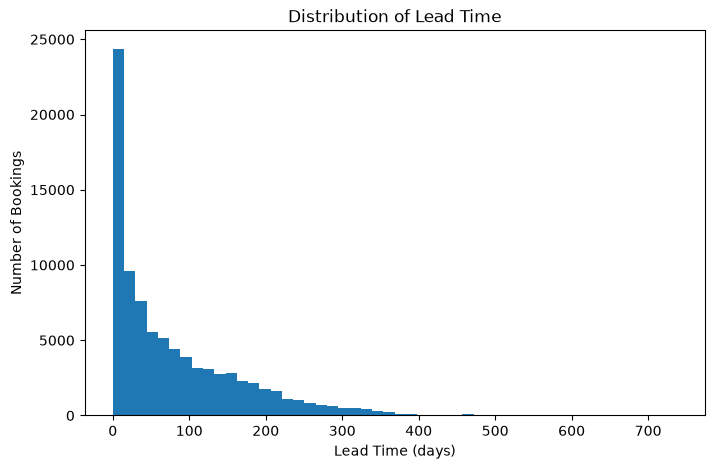

In [14]:
# Your code here
plt.figure(figsize=(8, 5))
plt.hist(df_clean["lead_time"], bins=50)
plt.title("Distribution of Lead Time")
plt.xlabel("Lead Time (days)")
plt.ylabel("Number of Bookings")
plt.show()

The histogram shows the distribution of lead time. Most bookings are made within a relatively short period before arrival, while fewer bookings are made far in advance

**Exercise 11.** Make a **bar chart** of the number of bookings per `hotel` (Resort vs City). Use `value_counts()` and label the chart.

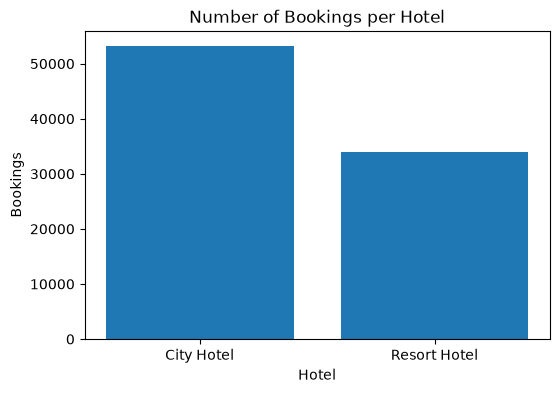

In [15]:
# Your code here
counts = df_clean["hotel"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values)
plt.title("Number of Bookings per Hotel")
plt.xlabel("Hotel")
plt.ylabel("Bookings")
plt.show()

**Exercise 12.** Draw a **scatter plot** of `lead_time` (x) vs `adr` (y). Use `alpha` and a small marker size `s` so the dense cloud is readable.

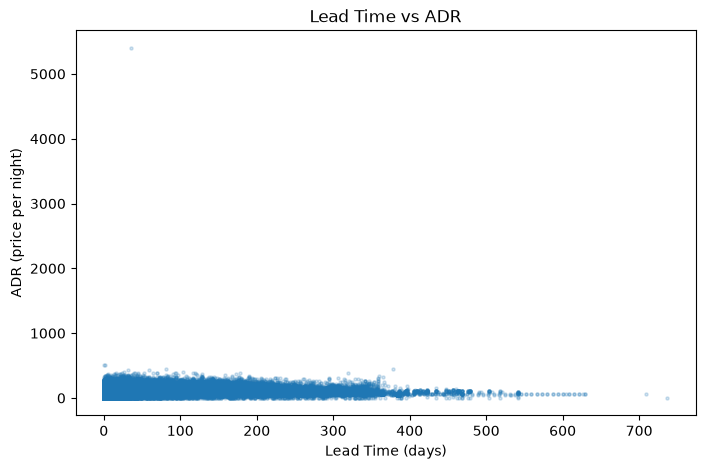

In [16]:
# Your code here
plt.figure(figsize=(8, 5))
plt.scatter(df_clean["lead_time"], df_clean["adr"], alpha=0.2, s=5)
plt.title("Lead Time vs ADR")
plt.xlabel("Lead Time (days)")
plt.ylabel("ADR (price per night)")
plt.show()

**Exercise 13.** Build a **2×2 grid of subplots** (`figsize=(12, 9)`):

- histogram of `adr`
- histogram of `total_guests`
- bar chart of `customer_type` counts
- bar chart of `is_canceled` counts (0 vs 1)

Give each subplot a title and call `fig.tight_layout()`.

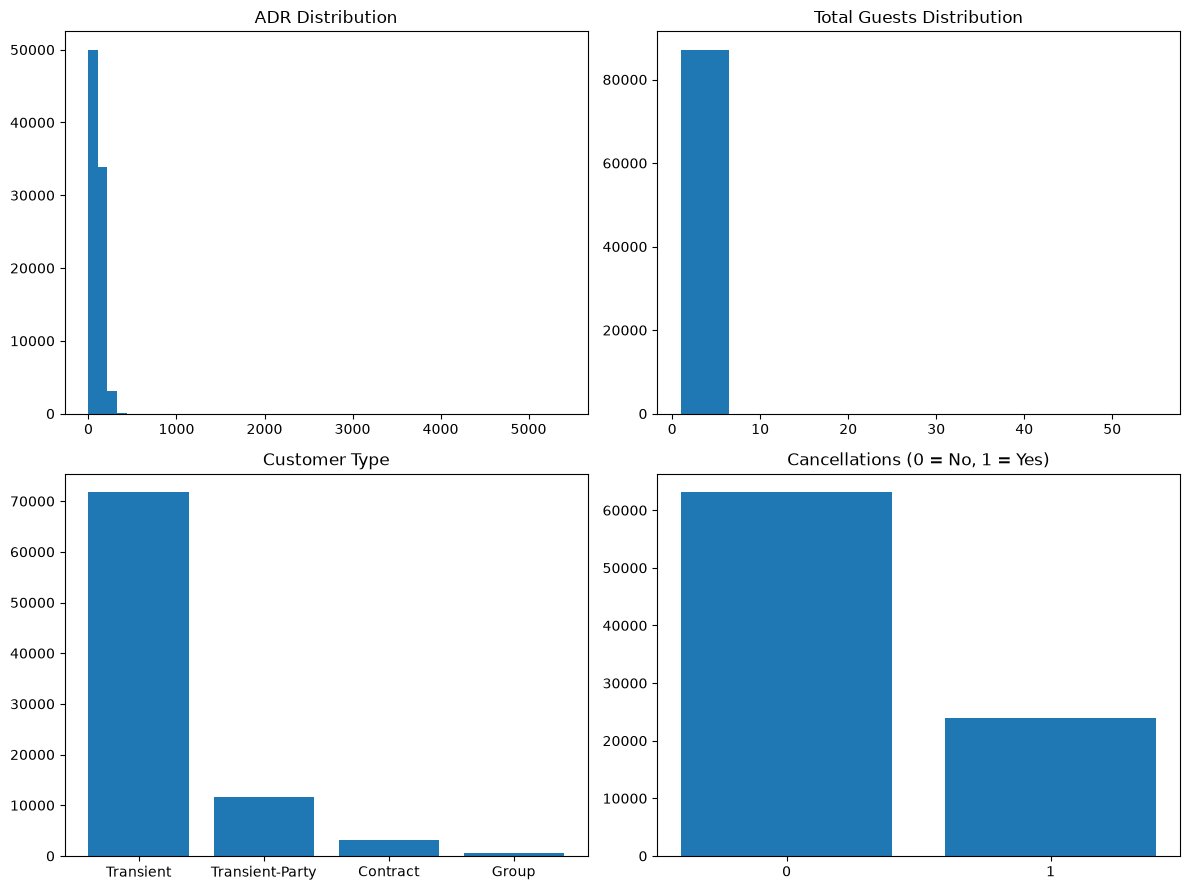

In [17]:
# Your code here
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].hist(df_clean["adr"], bins=50)
axes[0, 0].set_title("ADR Distribution")

axes[0, 1].hist(df_clean["total_guests"], bins=10)
axes[0, 1].set_title("Total Guests Distribution")

ct = df_clean["customer_type"].value_counts()
axes[1, 0].bar(ct.index, ct.values)
axes[1, 0].set_title("Customer Type")

ic = df_clean["is_canceled"].value_counts().sort_index()
axes[1, 1].bar(ic.index.astype(str), ic.values)
axes[1, 1].set_title("Cancellations (0 = No, 1 = Yes)")

fig.tight_layout()
plt.show()

**Exercise 14.** Compute the **correlation matrix** of the numeric columns and display it as a **heatmap** using `ax.imshow(..., cmap="coolwarm")`. Add a colorbar and tick labels with the column names.

*Tip: `df_clean.select_dtypes('number').corr()` gives the matrix; use `ax.set_xticks`/`set_yticks` + `set_xticklabels`/`set_yticklabels` for the labels.*

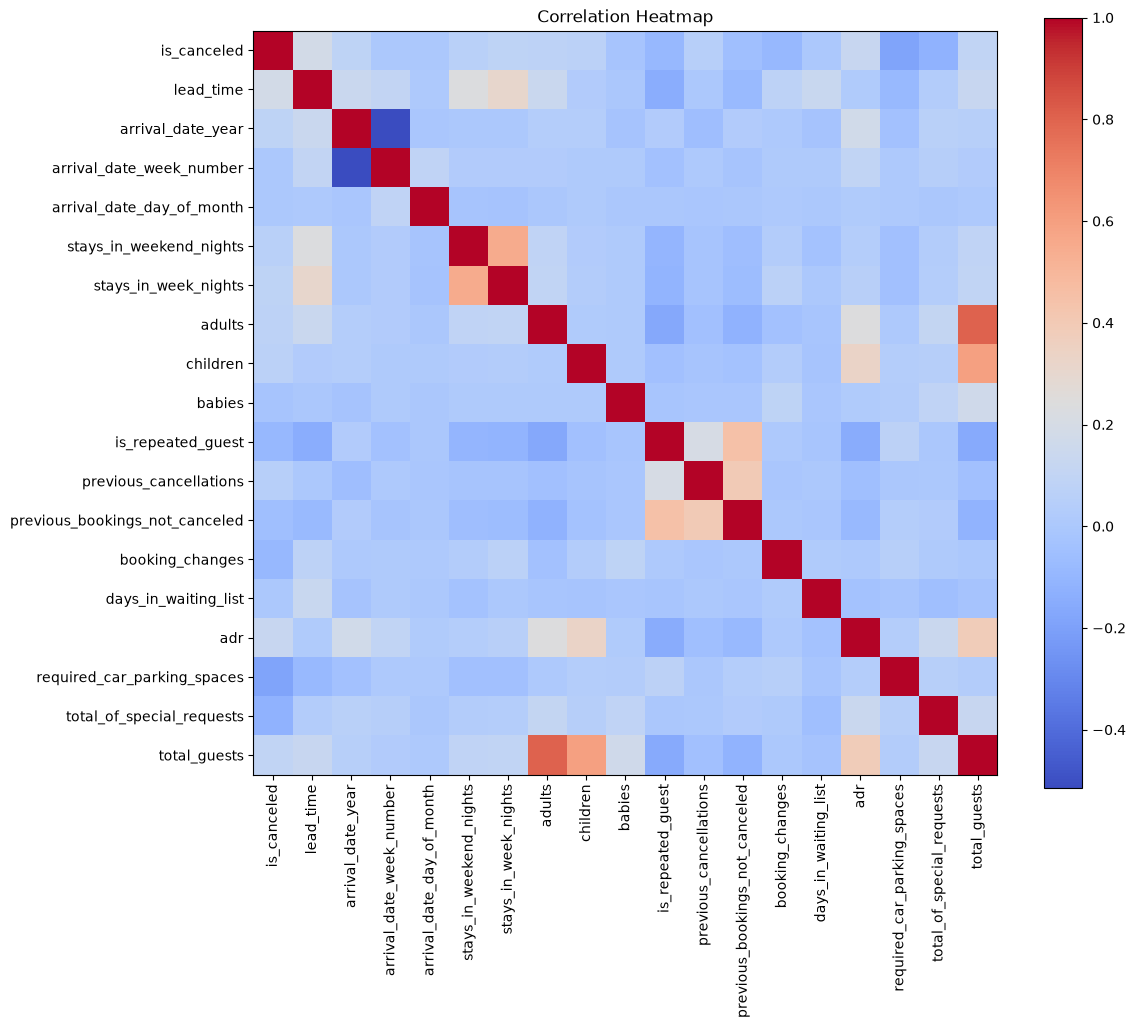

In [18]:
# Your code here
corr = df_clean.select_dtypes("number").corr()

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="coolwarm")
fig.colorbar(im)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)

ax.set_title("Correlation Heatmap")
plt.show()

The correlation matrix heatmap illustrates the relationships between numerical variables in the dataset. Positive values indicate positive correlations, while negative values indicate negative correlations. Values close to zero indicate weak linear relationships

# 4. Manipulating the Data

**Exercise 15.** **Sort** `df_clean` by `adr` in descending order and show the **top 10** most expensive bookings (columns `hotel`, `arrival_date_month`, `adr`).

In [19]:
# Your code here
top10 = df_clean.sort_values("adr", ascending=False).head(10)
top10[["hotel", "arrival_date_month", "adr"]]

,hotel,arrival_date_month,adr
48515,City Hotel,March,5400.00
111403,City Hotel,May,510.00
15083,Resort Hotel,July,508.00
103912,City Hotel,December,451.50
13142,Resort Hotel,August,450.00
13391,Resort Hotel,August,437.00
39155,Resort Hotel,August,426.25
39568,Resort Hotel,August,402.00
39118,Resort Hotel,July,397.38
39517,Resort Hotel,August,392.00


**Exercise 16.** Use boolean filtering to select **City Hotel bookings that were cancelled** (`hotel == "City Hotel"` **and** `is_canceled == 1`). How many are there?

In [20]:
# Your code here
city_canceled = df_clean[(df_clean["hotel"] == "City Hotel") & (df_clean["is_canceled"] == 1)]
print(len(city_canceled))

16033


**Exercise 17.** Group by `hotel` and compute the **mean `adr`** and the **cancellation rate** (mean of `is_canceled`) for each hotel. Which hotel cancels more?

In [21]:
# Your code here
result = df_clean.groupby("hotel").agg(
    mean_adr=("adr", "mean"),
    cancel_rate=("is_canceled", "mean")
)
result

,mean_adr,cancel_rate
hotel,,
City Hotel,111.274295,0.301033
Resort Hotel,99.073648,0.234864


In [22]:
result["cancel_rate"].idxmax()

'City Hotel'

**Exercise 18.** Produce a **grouped summary**: group by **both** `hotel` and `customer_type`, and aggregate `adr` with **mean, median and count** in one call.

In [ ]:
# Your code here
df_clean.groupby(["hotel", "customer_type"])["adr"].agg(["mean", "median", "count"])

**Exercise 19.** Build a **`crosstab`** of `hotel` (rows) vs `is_canceled` (columns) to count bookings in each combination.

In [23]:
# Your code here
pd.crosstab(df_clean["hotel"], df_clean["is_canceled"])

is_canceled,0,1
hotel,,
City Hotel,37227,16033
Resort Hotel,25971,7972


**Exercise 20.** Build a **`pivot_table`** with `hotel` as the index, `is_canceled` as the columns, and the **mean `adr`** as the values. Do cancelled bookings have a different average price?

In [25]:
# Your code here
pd.pivot_table(df_clean, index="hotel", columns="is_canceled", values="adr", aggfunc="mean")

is_canceled,0,1
hotel,,
City Hotel,108.643530,117.382665
Resort Hotel,93.016028,118.808024


# 5. Putting It Together

**Exercise 21.** Compute the **cancellation rate per arrival month** and plot it as a bar chart, with the months in **calendar order** (January → December), not alphabetical.

*Tip: group by `arrival_date_month`, take the mean of `is_canceled`, then `.reindex(...)` with a list of month names in order.*

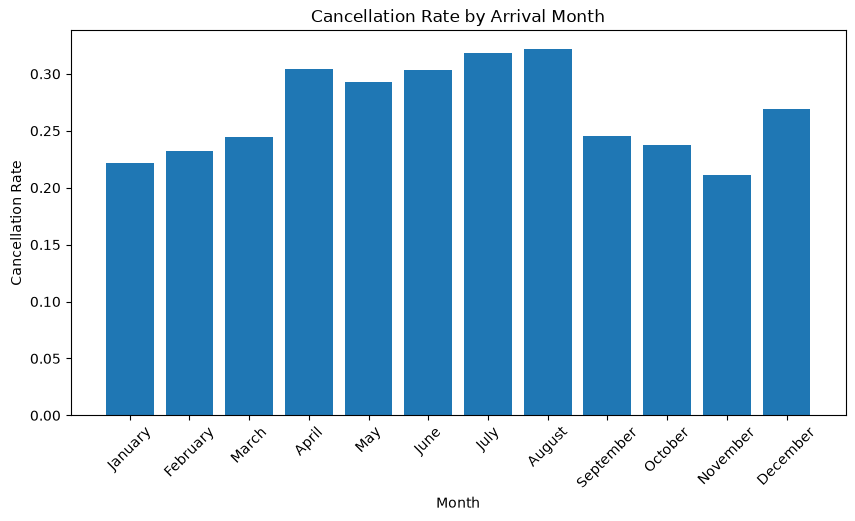

In [26]:
# Your code here
months = ["January", "February", "March", "April", "May", "June",
        "July", "August", "September", "October", "November", "December"]

monthly = df_clean.groupby("arrival_date_month")["is_canceled"].mean().reindex(months)

plt.figure(figsize=(10, 5))
plt.bar(monthly.index, monthly.values)
plt.xticks(rotation=45)
plt.title("Cancellation Rate by Arrival Month")
plt.xlabel("Month")
plt.ylabel("Cancellation Rate")
plt.show()

## 🏆 Challenge Exercises

These are open-ended — combine the skills above and explain what you find in a short comment.

1. **Total nights & revenue:** create `total_nights = stays_in_weekend_nights + stays_in_week_nights`, then estimate revenue as `adr * total_nights`. Which `market_segment` brings the most total estimated revenue? (Remember: cancelled bookings earn nothing — decide how to handle them and justify it.)
2. **Lead time vs cancellation:** bin `lead_time` into buckets (e.g. `pd.cut` at 0, 30, 90, 180, 365, ∞) and show the cancellation rate per bucket. Do bookings made far in advance get cancelled more?
3. **Repeat guests:** compare the cancellation rate of repeated guests (`is_repeated_guest == 1`) vs new guests. Visualize the difference.
4. **Your own question:** pose one question about the data, answer it with code + a plot, and write a one-line conclusion.

In [ ]:
# Your challenge code here
df_clean["total_nights"] = df_clean["stays_in_weekend_nights"] + df_clean["stays_in_week_nights"]
df_clean["revenue"] = df_clean["adr"] * df_clean["total_nights"]

not_canceled = df_clean[df_clean["is_canceled"] == 0]
not_canceled.groupby("market_segment")["revenue"].sum().sort_values(ascending=False)

market_segment
Online TA        12964173.81
Offline TA/TO     4593526.38
Direct            3925236.52
Groups             922772.97
Corporate          483070.83
Aviation            68968.36
Complementary        4804.53
Name: revenue, dtype: float64

<Axes: xlabel='lead_bucket'>

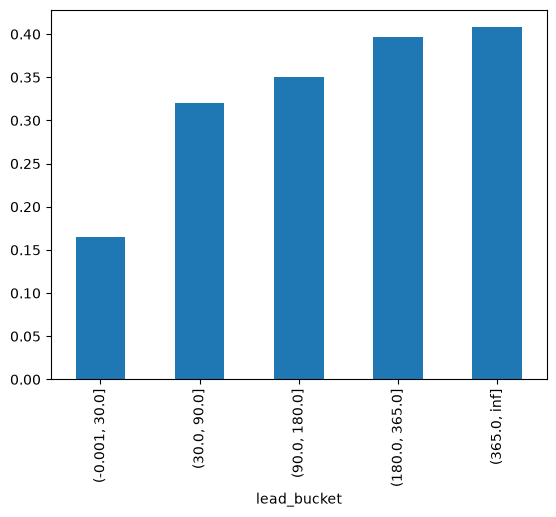

In [28]:
bins = [0, 30, 90, 180, 365, np.inf]
df_clean["lead_bucket"] = pd.cut(df_clean["lead_time"], bins=bins, include_lowest=True)
df_clean.groupby("lead_bucket", observed=True)["is_canceled"].mean().plot(kind="bar")

<Axes: xlabel='is_repeated_guest'>

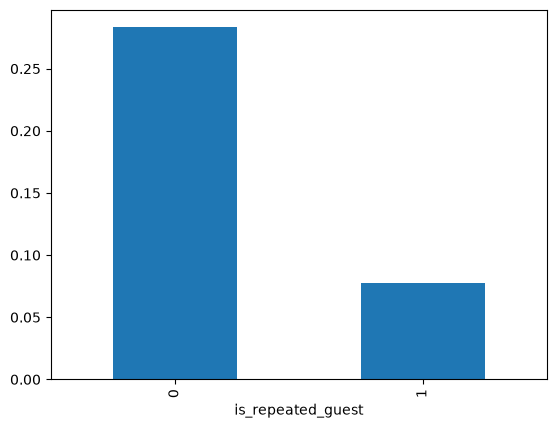

In [29]:
df_clean.groupby("is_repeated_guest")["is_canceled"].mean().plot(kind="bar")

## Conclusion

In a short markdown note below, summarise **3 things you learned** about hotel bookings from this analysis (e.g. which hotel cancels more, when cancellations peak, what drives price).

*Write your conclusions here...*